Today's topics:

* materials databases and APIs
* querying Materials Project from Python
* building a DataFrame from query results

# Silicon, germanium, and tin crystals

So far we have loaded tables supplied with the course.
Today we will get materials data from a public database ourselves.

Silicon (Si), germanium (Ge), and tin (Sn) sit in the same column of the periodic table.
Silicon and germanium are semiconductors.
Tin is a metal at room temperature.

Below 13 °C, tin can slowly turn into brittle gray tin.
This is called **tin pest**.

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/2/2b/Sn-Alpha-Beta.jpg/960px-Sn-Alpha-Beta.jpg" alt="Two boxes of tin beads: shiny white tin on the left, dull gray tin on the right" width="500"/>

*Photo by Alchemist-hp, [CC BY-SA 3.0 DE](https://creativecommons.org/licenses/by-sa/3.0/de/deed.en), [via Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Sn-Alpha-Beta.jpg).*

Above: pure tin as shiny white β-Sn (left) and dull gray α-Sn (right).

Which of these elements has the densest crystal?

# Materials Project

## What is Materials Project?

> "The Materials Project is a multi-institution, multi-national effort to compute the properties of all inorganic materials and provide the data and associated analysis algorithms for every materials researcher free of charge. The ultimate goal of the initiative is to drastically reduce the time needed to invent new materials by focusing costly and time-consuming experiments on compounds that show the most promise computationally."

https://next-gen.materialsproject.org/about

## How are the calculations performed?

The crystal properties we use today are computed with **density functional theory (DFT)**.

DFT works with the electron density instead of each electron's wavefunction.
That makes the quantum mechanics feasible to solve.

<img src="https://d3i71xaburhd42.cloudfront.net/3262f9f1418d1bcfd6be316fef39103b8b5fbc53/22-Figure3.1-1.png" width=500>

> Hohenberg and Kohn (1964) showed that the ground-state density determines the energy. The Kohn-Sham equations (1965) made the calculation practical. The exchange-correlation functional is the approximation. It is still an active area of research.

These calculations are for perfect crystals at **0 K**, the so-called **ground state**.

Entropy is left out.
A material that looks fantastic at 0 K can decompose at room temperature, or lose its desirable properties.

Check the temperature and crystal structure before comparing a value with a real sample.

<img src="https://media.springernature.com/full/springer-static/image/art%3A10.1007%2Fs11095-018-2374-9/MediaObjects/11095_2018_2374_Fig2_HTML.gif?as=webp" width=500>

> Hadjittofis, Eftychios, et al. "Influences of crystal anisotropy in pharmaceutical process development." *Pharmaceutical Research* 35 (2018): 1-22.

> We will run basic DFT calculations ourselves in MATSE 419.

# Databases and APIs

## Materials databases

A **database** holds records we can search.
A crystal's record has an ID, a composition, a structure, and properties.

Materials Project is one of several:

| Database | What it holds | Access |
|---|---|---|
| [Materials Project](https://next-gen.materialsproject.org/) | calculated inorganic crystals | free account |
| [OQMD](https://www.oqmd.org/) | calculated structures and energies | open |
| [JARVIS-DFT](https://jarvis.nist.gov/) (NIST) | calculated structures and properties | open |
| [NOMAD](https://nomad-lab.eu/) | computational and experimental records with source files | open |
| [ICSD](https://icsd.products.fiz-karlsruhe.de/) | measured crystal structures | paid license |

Before comparing two values, ask whether each was calculated or measured.

## The Materials Project web app

Let's explore the [Materials Project](https://next-gen.materialsproject.org/) website first.
Later we'll get the same data with Python.

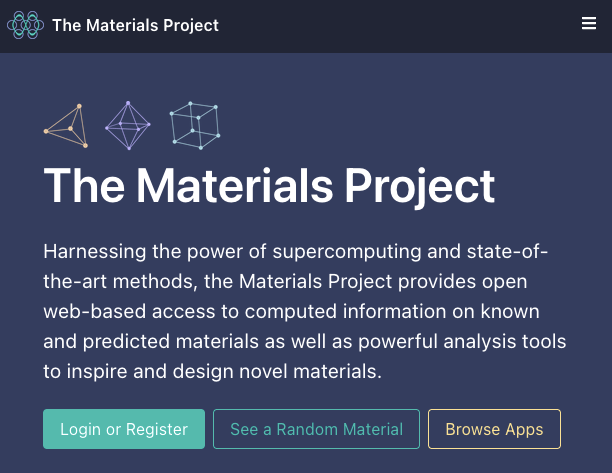

"Login or Register" ➡ log in with a Google account or an email login.

> If you followed the Canvas setup checklist, you already have an account.

Go to "Apps" ➡ "Materials Explorer".
We'll start with something simple:

* Search for the Fe symbol

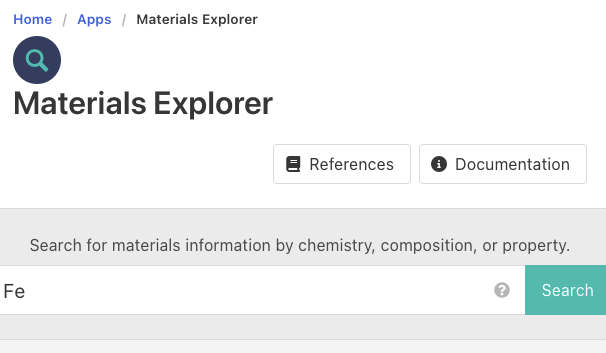

* Choose "Is Stable"

> This leaves one material. The other forms of elemental Fe are not the lowest-energy state.

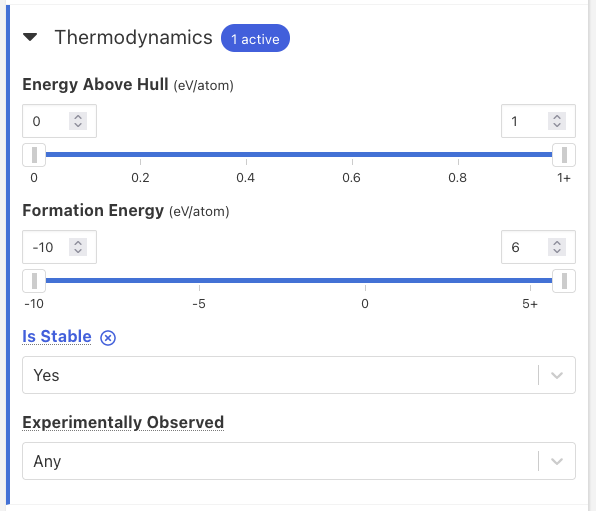

Here is the list of results.

> Click the ❌ to remove "Is Stable" and you will see the other forms of Fe.

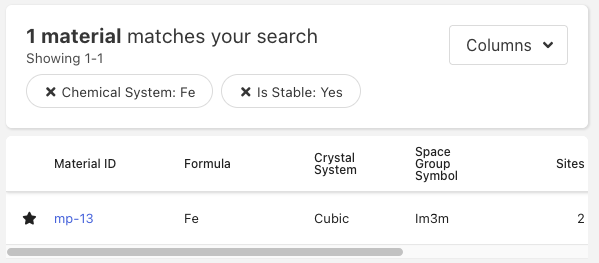

"Columns" chooses which information is displayed.

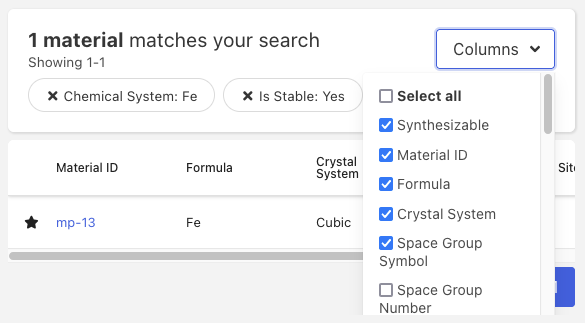

The [mp-13](https://next-gen.materialsproject.org/materials/mp-13?chemsys=Fe&is_stable=1) page has many more details, including a 3D crystal structure viewer:

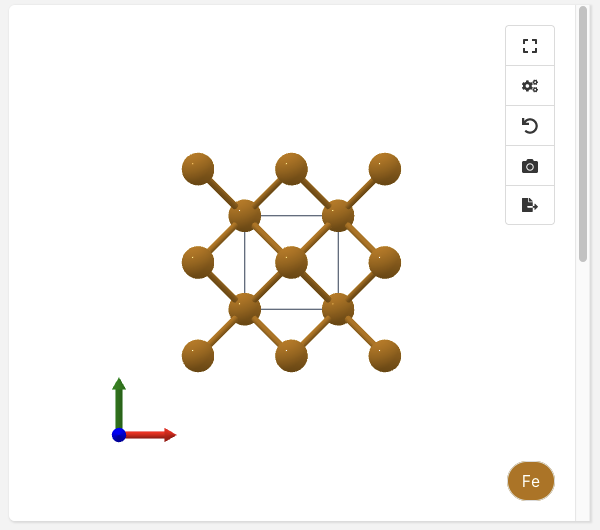

Scroll down for structural, magnetic, electronic, thermodynamic, and mechanical properties.
Here is the elastic property data:

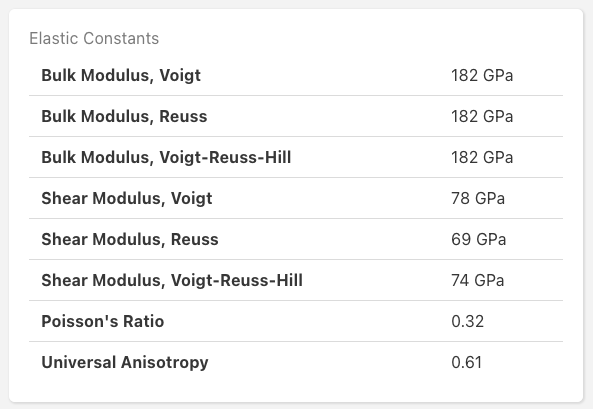

### [Check your understanding]

1. Use the website to look up the stable elemental entries for Si, Ge, and Sn.
   * Record each material ID, density, and space group.
2. Type your values into a DataFrame with columns `'symbol'`, `'material_id'`, `'density'`, and `'space_group'`.
   * Display it.

What if we kept going down the column, to C and Pb?
What if we went back and added the unit cell volume for each one?

How much more work is that by hand?

## What is an API?

An **Application Programming Interface (API)** is a set of rules that lets one program request data from another.

* **Endpoint:** a URL for one kind of resource, like material summaries
* **Request:** what we ask for: parameters and our key
* **Response:** the data that comes back, usually as **JSON**
* **Documentation:** the list of endpoints and parameters

> The Materials Project endpoints are listed [here](https://api.materialsproject.org/docs).

## Obtaining an API key

A **key** is a unique code that identifies you to the API.

Materials Project is free and runs on research funding.
The key lets them track usage (to show how much the community uses it) and limit how many requests one user makes.

> Never share your key or leave it in a notebook you submit. It identifies you!

Top right menu ➡ API ➡ scroll down to "API Key"

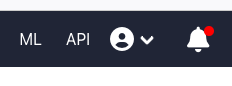

In Colab, store the key as a secret named `MaterialsProject`, as in the Canvas setup checklist.

## Installing `mp-api`

Materials Project provides a Python package, `mp-api`.

`pip` is Python's package manager.
The `!` sends the command to the operating system instead of Python.

> ⏳ This could take a few minutes.

In [ ]:
!pip install mp-api==0.47.0

In [2]:
#@title Read your Materials Project key (click ▶ to run) { display-mode: "form" }
try:
    from google.colab import userdata
    API_KEY = userdata.get('MaterialsProject')
except ImportError:
    import os
    API_KEY = os.environ['MP_API_KEY']

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from mp_api.client import MPRester

# Querying Materials Project from Python

## A first request

Let's ask for the structure of `mp-149` (silicon):

In [4]:
with MPRester(API_KEY) as mpr:
    silicon_docs = mpr.materials.summary.search(material_ids=['mp-149'], fields=['structure'])

display(silicon_docs[0].structure)

✓ Retrieved 1 SummaryDoc documents in 0.6s

Structure Summary
Lattice
    abc : 3.8492784033699095 3.8492794116013456 3.849278
 angles : 60.00001213094421 60.00000346645984 60.00001097545789
 volume : 40.32952684741405
      A : 3.333573 0.0 1.924639
      B : 1.111191 3.142924 1.924639
      C : 0.0 0.0 3.849278
    pbc : True True True
PeriodicSite: Si (3.889, 2.75, 6.736) [0.875, 0.875, 0.875]
PeriodicSite: Si (0.5556, 0.3929, 0.9623) [0.125, 0.125, 0.125]

Two Si atoms in the primitive cell of diamond cubic.

`MPRester` is a **client**.
It handles the communication with the API for us.

Here is a request for the same material without the client, asking for two simpler fields:

In [5]:
import requests

response = requests.get('https://api.materialsproject.org/materials/summary/?material_ids=mp-149&_fields=formula_pretty,density',
                        headers={'X-API-KEY': API_KEY})  # the key travels with the request

print(response.text)  # the raw JSON response

{"data":[{"formula_pretty":"Si","density":2.3128002565764314}],"meta":{"api_version":"0.88.1","time_stamp":"2026-11-06T16:00:32.506928+00:00","total_doc":1,"facet":null,"max_limit":1000,"default_fields":["material_id"]}}


Same density as the website!

The URL points to the `materials/summary` **endpoint**.
The parameters after `?` select `mp-149` and the two fields we want.

The client builds this request and unpacks the JSON for us.

## Searching with filters

Let's search for materials made only of Ga:

In [6]:
with MPRester(API_KEY) as mpr:
    gallium_docs = mpr.materials.summary.search(chemsys='Ga', fields=['material_id'])

print(len(gallium_docs))  # number of matching entries

✓ Retrieved 8 SummaryDoc documents in 0.8s

8


Many structures are possible.
Let's keep only the stable one and ask for its density too:

In [7]:
with MPRester(API_KEY) as mpr:
    gallium_docs = mpr.materials.summary.search(
        chemsys='Ga',
        num_elements=1,  # only one element in the material
        is_stable=True,  # only the lowest-energy structure
        fields=['material_id', 'density'],
    )

print(len(gallium_docs))

✓ Retrieved 1 SummaryDoc documents in 0.9s

1


That's the same filter as the "Is Stable" checkbox on the website.

`search` returns a list of documents, even when there is only one.
A dot reads each requested field:

In [8]:
gallium = gallium_docs[0]
print(gallium.material_id)
print(gallium.density)  # in g/cm³

mp-142
6.037763290229381


Each search returns a list of documents.

We can turn each document into a dictionary.
Each dictionary becomes one row of a DataFrame:

### [Check your understanding]

Let's automate the Si, Ge, and Sn table from the website.

1. Make `elements = ['Si', 'Ge', 'Sn']` and an empty list `records`.
2. Inside one `with MPRester(API_KEY)` block, loop over the symbols.
   * Search for stable elemental entries.
   * Request `material_id` and `density`.
3. For each returned document, append a dictionary with keys `'symbol'`, `'material_id'`, and `'density'`.
4. Make a DataFrame `crystals` from `records` and display it.

Do the values match the ones you found on the website?

## Compare with a worked version

In [9]:
elements = ['Si', 'Ge', 'Sn']
records = []

with MPRester(API_KEY) as mpr:
    for symbol in elements:
        docs = mpr.materials.summary.search(
            chemsys=symbol,
            num_elements=1,
            is_stable=True,
            fields=['material_id', 'density'],
        )
        print(symbol, len(docs))  # check how many entries matched each query
        for doc in docs:
            records.append({
                'symbol': symbol,
                'material_id': str(doc.material_id),  # convert the ID object to plain text
                'density': doc.density,
            })

crystals = pd.DataFrame(records)
display(crystals)

✓ Retrieved 1 SummaryDoc documents in 0.8s

Si 1


✓ Retrieved 1 SummaryDoc documents in 0.8s

Ge 1


✓ Retrieved 1 SummaryDoc documents in 0.8s

Sn 1


,symbol,material_id,density
0,Si,mp-149,2.312800
1,Ge,mp-32,5.280205
2,Sn,mp-117,5.560776


To add C and Pb, we only need to edit `elements`.
To add a property, we add its name to `fields`.

Results can change when Materials Project updates its database.
Record the database version with the material IDs:

In [10]:
with MPRester(API_KEY) as mpr:
    database_version = mpr.db_version

print(database_version)

2026.09.28


## Which crystal is densest?

Text(0, 0.5, 'computed density (g/cm³)')

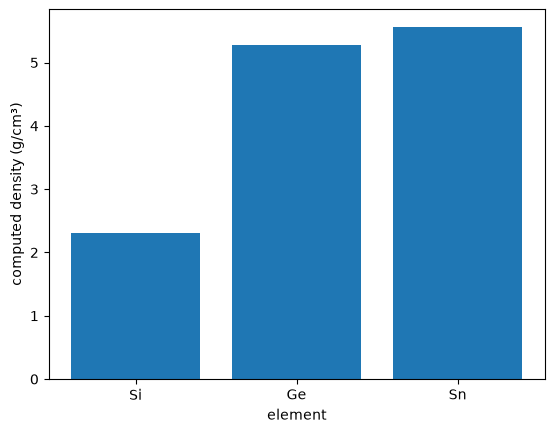

In [11]:
fig, ax = plt.subplots()
ax.bar(crystals['symbol'], crystals['density'])
ax.set_xlabel('element')
ax.set_ylabel('computed density (g/cm³)')

Sn is the densest, but only slightly denser than Ge.

All three have space group Fd-3m, the diamond structure.

A Sn atom is much heavier than a Ge atom.
The Sn unit cell is also larger: about 6.49 Å on a side, versus 5.66 Å for Ge.

> The [measured](https://nvlpubs.nist.gov/nistpubs/jres/68A/jresv68An5p529_A1b.pdf) density of silicon at 25 °C is 2.329 g/cm³. The calculated value is 2.313 g/cm³.

## Gray tin and white tin

The `is_stable` filter gave us gray α-Sn, the ground state at 0 K.
The tin we handle at room temperature is white β-Sn.

<img src="https://upload.wikimedia.org/wikipedia/commons/6/61/Tin_allotropy.jpg" alt="Unit cells of white beta tin and gray alpha tin, with cooling below 13.2 degrees C converting one to the other" width="500"/>

*Image by DanyelODACI, [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0), [via Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Tin_allotropy.jpg).*

Above: cooling turns white β-Sn into gray α-Sn, the diamond structure.

Let's retrieve both by material ID:

In [12]:
with MPRester(API_KEY) as mpr:
    tin_docs = mpr.materials.summary.search(
        material_ids=['mp-117', 'mp-84'],  # gray α-Sn and white β-Sn
        fields=['material_id', 'density', 'is_stable'],
    )

for doc in tin_docs:
    print(doc.material_id, doc.density, doc.is_stable)

✓ Retrieved 2 SummaryDoc documents in 0.0s

mp-117 5.560776479834602 True
mp-84 7.129183189177697 False


White tin is about 28% denser than gray tin!

The same atoms take up more room in gray tin.
That is why tin pest makes tin swell and crumble.

A handbook gives about 7.3 g/cm³ for white tin, 2% above the computed 7.13 g/cm³.

# Summary

* Materials Project reports properties calculated with DFT for perfect crystals at 0 K.
* An API is a set of rules for requesting data: endpoints, requests, and JSON responses.
* An API key identifies you; keep it in a Colab secret.
* A search filters records and requests named fields; dot notation reads a document's fields.
* Dictionaries made from returned documents can become DataFrame rows.
* Material IDs and the database version belong with reported computed values.

## Further reading

* Materials Project, [Getting Started with the API](https://docs.materialsproject.org/downloading-data/using-the-api/getting-started)
* Materials Project, [Querying Data](https://docs.materialsproject.org/downloading-data/using-the-api/querying-data)
* Materials Project, [Database Versions](https://docs.materialsproject.org/changes/database-versions)
* M. K. Horton et al., ["Accelerated data-driven materials science with the Materials Project"](https://doi.org/10.1038/s41563-025-02272-0), *Nature Materials* **24**, 1522–1532 (2025). The Materials Project data used here are shared under [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

# Appendix A: Other endpoints

Specialized data, like the elastic tensor, comes from a different endpoint, `elasticity`:

In [13]:
with MPRester(API_KEY) as mpr:
    elastic_docs = mpr.materials.elasticity.search(material_ids=['mp-149'])

silicon_elastic = elastic_docs[0]
print(silicon_elastic.bulk_modulus)  # three averages of the bulk modulus, in GPa

✓ Retrieved 1 ElasticityDoc documents in 0.1s

voigt=88.916 reuss=88.916 vrh=88.916


Getting data often takes more than one call:

1. search one endpoint for the IDs that match our criteria
2. request each property from its own endpoint